# Phase 3: Exploratory Data Analysis (EDA)
## Customer Churn Prediction System

This notebook investigates the IBM Telco Customer Churn dataset, uncovers behavioral and contract drivers of customer churn, explores bivariate relationships with the target variable, and documents business insights.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from churn_prediction.config import (
    ALL_FEATURE_COLS,
    NUMERICAL_FEATURES,
    CATEGORICAL_FEATURES,
    TARGET_COL,
    TARGET_LABEL_COL,
    FIGURES_DIR,
)
from churn_prediction.data_loader import load_raw_data

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.dpi"] = 120
%matplotlib inline

### 1. Ingestion and Structural Overview
We load the raw dataset through the project data-loader module.

In [2]:
df_raw = load_raw_data(use_cache=True)
print(f"Dataset Dimensions: {df_raw.shape[0]} rows, {df_raw.shape[1]} columns")
df_raw.head(3)

Dataset Dimensions: 7043 rows, 33 columns


,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,...,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,...,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,...,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,...,Month-to-month,Yes,Electronic check,99.65,820.5,Yes,1,86,5372,Moved


In [3]:
# Check data types and non-null counts
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 33 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         7043 non-null   str    
 1   Count              7043 non-null   int64  
 2   Country            7043 non-null   str    
 3   State              7043 non-null   str    
 4   City               7043 non-null   str    
 5   Zip Code           7043 non-null   int64  
 6   Lat Long           7043 non-null   str    
 7   Latitude           7043 non-null   float64
 8   Longitude          7043 non-null   float64
 9   Gender             7043 non-null   str    
 10  Senior Citizen     7043 non-null   str    
 11  Partner            7043 non-null   str    
 12  Dependents         7043 non-null   str    
 13  Tenure Months      7043 non-null   int64  
 14  Phone Service      7043 non-null   str    
 15  Multiple Lines     7043 non-null   str    
 16  Internet Service   7043 non-null   

### 2. Target Variable & Class Imbalance Analysis
We inspect the distribution of `Churn Label` and `Churn Value`.

,Count,Percentage (%)
Churn Label,,
No,5174,73.46
Yes,1869,26.54


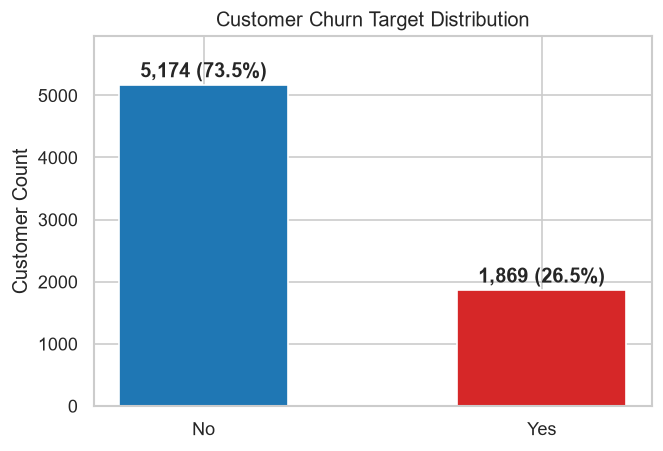

In [4]:
churn_counts = df_raw["Churn Label"].value_counts()
churn_pcts = df_raw["Churn Label"].value_counts(normalize=True) * 100

summary_df = pd.DataFrame({"Count": churn_counts, "Percentage (%)": churn_pcts.round(2)})
display(summary_df)

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(churn_counts.index, churn_counts.values, color=["#1f77b4", "#d62728"], width=0.5)
for bar, pct in zip(bars, churn_pcts.values):
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width() / 2, yval + 50, f"{yval:,} ({pct:.1f}%)", ha="center", va="bottom", fontweight="bold")
ax.set_title("Customer Churn Target Distribution", fontsize=12)
ax.set_ylabel("Customer Count")
ax.set_ylim(0, churn_counts.max() * 1.15)
plt.show()

### 3. Univariate & Bivariate Analysis of Key Features
#### A. Customer Tenure Dynamics
We analyze how customer tenure differs between churned and retained subscribers.

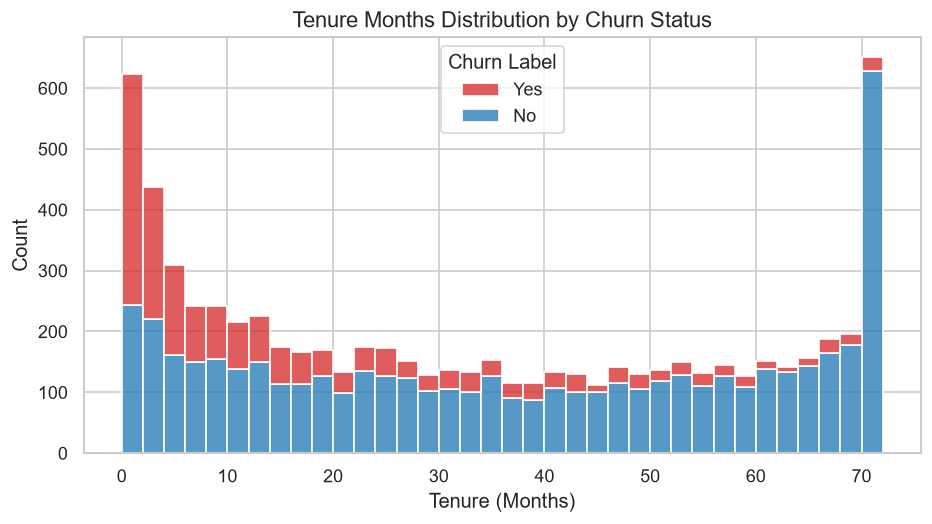

Median Tenure by Churn Status:
Churn Label
No     38.0
Yes    10.0
Name: Tenure Months, dtype: float64


In [5]:
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.histplot(
    data=df_raw,
    x="Tenure Months",
    hue="Churn Label",
    multiple="stack",
    palette={"No": "#1f77b4", "Yes": "#d62728"},
    bins=36,
    ax=ax,
)
ax.set_title("Tenure Months Distribution by Churn Status", fontsize=13)
ax.set_xlabel("Tenure (Months)")
plt.show()

print("Median Tenure by Churn Status:")
print(df_raw.groupby("Churn Label")["Tenure Months"].median())

#### B. Monthly Charges vs. Churn
We explore the distribution of monthly billing rates.

C:\Users\USER\AppData\Local\Temp\ipykernel_19916\1008936611.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


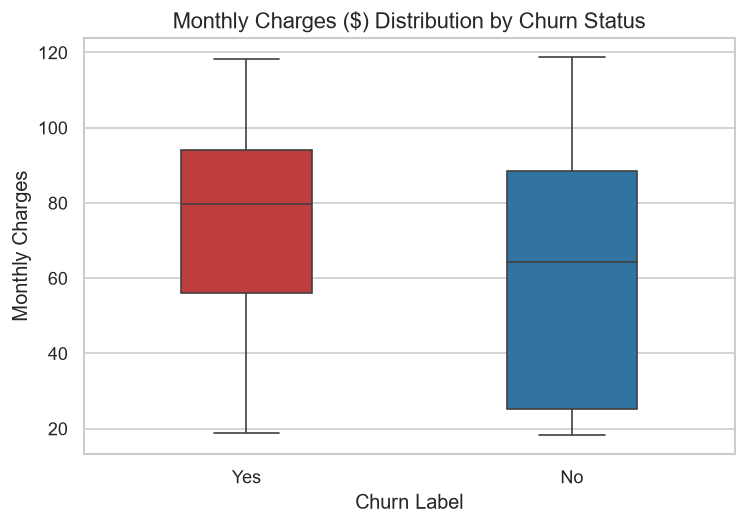

Monthly Charges Summary by Churn Status:
              count   mean    std    min    25%    50%   75%     max
Churn Label                                                         
No           5174.0  61.27  31.09  18.25  25.10  64.43  88.4  118.75
Yes          1869.0  74.44  24.67  18.85  56.15  79.65  94.2  118.35


In [6]:
fig, ax = plt.subplots(figsize=(7, 4.5))
sns.boxplot(
    data=df_raw,
    x="Churn Label",
    y="Monthly Charges",
    palette={"No": "#1f77b4", "Yes": "#d62728"},
    ax=ax,
    width=0.4,
)
ax.set_title("Monthly Charges ($) Distribution by Churn Status", fontsize=13)
plt.show()

print("Monthly Charges Summary by Churn Status:")
print(df_raw.groupby("Churn Label")["Monthly Charges"].describe().round(2))

#### C. Contract Type Impact
We evaluate churn rates across contract types.

,Contract,count,mean,Churn Rate (%)
0,Month-to-month,3875,0.427097,42.71
1,One year,1473,0.112695,11.27
2,Two year,1695,0.028319,2.83


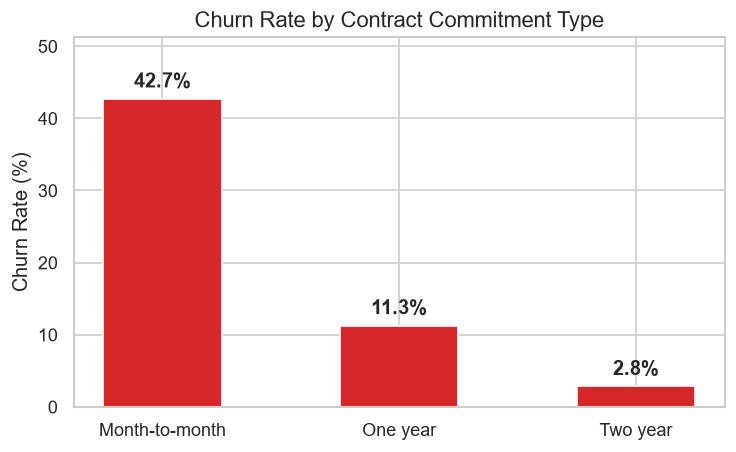

In [7]:
contract_churn = df_raw.groupby("Contract")["Churn Value"].agg(["count", "mean"]).reset_index()
contract_churn["Churn Rate (%)"] = (contract_churn["mean"] * 100).round(2)
contract_churn = contract_churn.sort_values(by="Churn Rate (%)", ascending=False)
display(contract_churn)

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(contract_churn["Contract"], contract_churn["Churn Rate (%)"], color="#d62728", width=0.5)
for bar in bars:
    h = bar.get_height()
    ax.text(bar.get_x() + bar.get_width() / 2, h + 1, f"{h:.1f}%", ha="center", va="bottom", fontweight="bold")
ax.set_title("Churn Rate by Contract Commitment Type", fontsize=13)
ax.set_ylabel("Churn Rate (%)")
ax.set_ylim(0, contract_churn["Churn Rate (%)"].max() * 1.2)
plt.show()

#### D. Internet Service and Value-Added Tech Support
We investigate how Tech Support affects retention across internet service tiers.

,Internet Service,Tech Support,count,mean,Churn Rate (%)
0,DSL,No,1243,0.277554,27.76
1,DSL,Yes,1178,0.096774,9.68
2,Fiber optic,No,2230,0.493722,49.37
3,Fiber optic,Yes,866,0.226328,22.63
4,No,No internet service,1526,0.074050,7.40


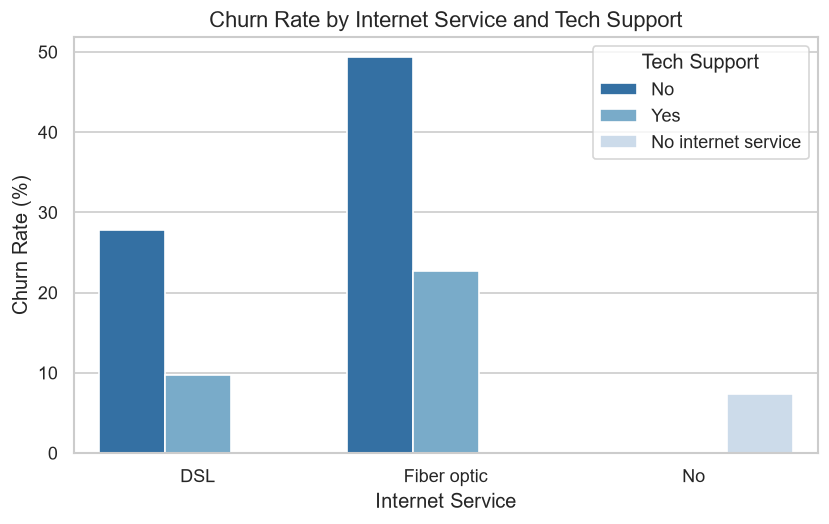

In [8]:
service_churn = df_raw.groupby(["Internet Service", "Tech Support"])["Churn Value"].agg(["count", "mean"]).reset_index()
service_churn["Churn Rate (%)"] = (service_churn["mean"] * 100).round(2)
display(service_churn)

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.barplot(
    data=service_churn,
    x="Internet Service",
    y="Churn Rate (%)",
    hue="Tech Support",
    palette="Blues_r",
    ax=ax,
)
ax.set_title("Churn Rate by Internet Service and Tech Support", fontsize=13)
plt.show()

#### E. Payment Method Analysis

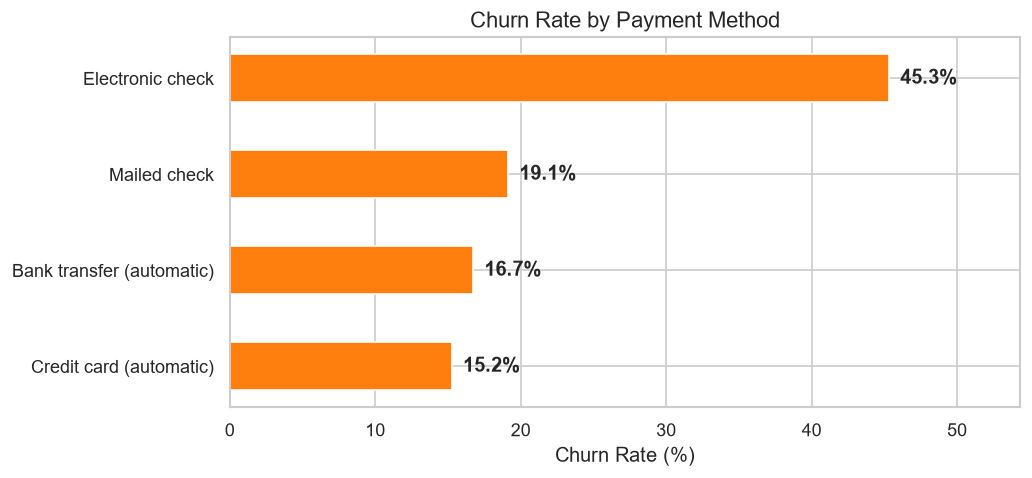

In [9]:
pm_churn = df_raw.groupby("Payment Method")["Churn Value"].agg(["count", "mean"]).reset_index()
pm_churn["Churn Rate (%)"] = (pm_churn["mean"] * 100).round(2)
pm_churn = pm_churn.sort_values(by="Churn Rate (%)", ascending=True)

fig, ax = plt.subplots(figsize=(8.5, 4))
bars = ax.barh(pm_churn["Payment Method"], pm_churn["Churn Rate (%)"], color="#ff7f0e", height=0.5)
for bar in bars:
    w = bar.get_width()
    ax.text(w + 0.8, bar.get_y() + bar.get_height() / 2, f"{w:.1f}%", ha="left", va="center", fontweight="bold")
ax.set_title("Churn Rate by Payment Method", fontsize=13)
ax.set_xlabel("Churn Rate (%)")
ax.set_xlim(0, pm_churn["Churn Rate (%)"].max() * 1.2)
plt.show()

### 4. Multivariate Numerical Correlations

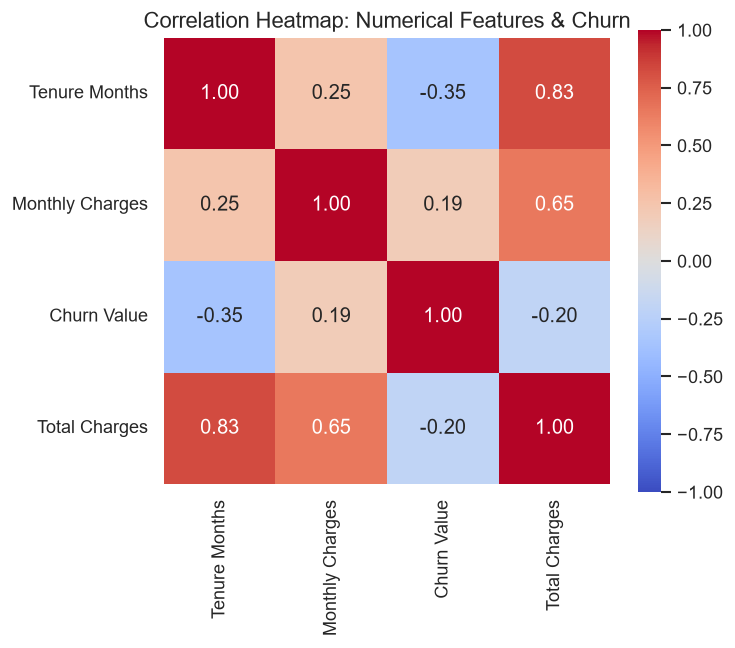

In [10]:
tc_clean = pd.to_numeric(df_raw["Total Charges"].astype(str).str.strip(), errors="coerce").fillna(0.0)
df_corr = df_raw[["Tenure Months", "Monthly Charges", "Churn Value"]].copy()
df_corr["Total Charges"] = tc_clean

corr_matrix = df_corr.corr()
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True, ax=ax)
ax.set_title("Correlation Heatmap: Numerical Features & Churn", fontsize=13)
plt.show()

### 5. Summary of EDA Findings
1. **Tenure Decay:** Over 50% of churn occurs in the first 12 months; median tenure for churners is 10 months vs 38 months for loyal customers.
2. **Contract Lock-in:** Month-to-month contracts exhibit a 42.7% churn rate, compared to 11.3% for 1-year and 2.8% for 2-year contracts.
3. **High-Speed Friction:** Fiber optic customers churn at 41.9%, but adding Tech Support cuts churn by more than half.
4. **Billing Friction:** Electronic check payers churn at 45.3% vs ~15.5% for automatic credit card or bank transfer.